# MNIST Data Exploration

Explore the MNIST handwritten-digit dataset before building the NumPy MLP.

**Goals**
- Load and validate the official train and test splits.
- Inspect image dimensions, labels, class balance, and pixel values.
- Visualize representative digits and aggregate pixel patterns.

The test split is reserved for final evaluation. Do not use it to make training or model-selection decisions.
TensorFlow is used only as a dataset-loading utility; the MLP implementation will use NumPy.

In [1]:

import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
from tensorflow.keras.datasets import mnist

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams.update(
    {
        "figure.figsize": (10, 5),
        "image.cmap": "gray",
        "axes.titlesize": 10,
    }
)

print(f"NumPy version: {np.__version__}")
print("MNIST loader: tensorflow.keras.datasets")

NumPy version: 2.2.6
MNIST loader: tensorflow.keras.datasets


## Load the dataset

`mnist.load_data()` downloads the files on first use and caches them in Keras's local data cache.
The returned images are grayscale `uint8` arrays with pixel values from 0 to 255.

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print(f"Training images: {X_train.shape}, dtype={X_train.dtype}")
print(f"Training labels: {y_train.shape}, dtype={y_train.dtype}")
print(f"Test images:     {X_test.shape}, dtype={X_test.dtype}")
print(f"Test labels:     {y_test.shape}, dtype={y_test.dtype}")

Training images: (60000, 28, 28), dtype=uint8
Training labels: (60000,), dtype=uint8
Test images:     (10000, 28, 28), dtype=uint8
Test labels:     (10000,), dtype=uint8


In [3]:
# Verify the expected MNIST structure and basic data integrity.
assert X_train.shape == (60_000, 28, 28)
assert y_train.shape == (60_000,)
assert X_test.shape == (10_000, 28, 28)
assert y_test.shape == (10_000,)
assert X_train.dtype == np.uint8
assert X_test.dtype == np.uint8
assert np.isfinite(X_train).all()
assert np.isfinite(X_test).all()
assert set(np.unique(y_train)) == set(range(10))
assert set(np.unique(y_test)) == set(range(10))

print(f"Train pixel range: {X_train.min()}–{X_train.max()}")
print(f"Test pixel range:  {X_test.min()}–{X_test.max()}")
print("Dataset checks passed.")

Train pixel range: 0–255
Test pixel range:  0–255
Dataset checks passed.


## Class balance

Check whether the training labels are reasonably balanced. The test labels are shown for descriptive
purposes only; keep that split reserved for final evaluation.

In [4]:
classes = np.arange(10)
train_counts = np.bincount(y_train, minlength=10)
test_counts = np.bincount(y_test, minlength=10)

fig = px.bar(
    x=classes,
    y=train_counts,
    labels={"x": "Digit", "y": "Image count"},
    title="MNIST training examples per digit",
)
fig.update_layout(xaxis=dict(tickmode="linear", dtick=1))
fig.show()

print("Training counts:", train_counts.tolist())
print("Test counts:    ", test_counts.tolist())

Training counts: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]
Test counts:     [980, 1135, 1032, 1010, 982, 892, 958, 1028, 974, 1009]


## Inspect example images

Show one training image for each digit. Each image remains a 28 × 28 grayscale array at this stage.

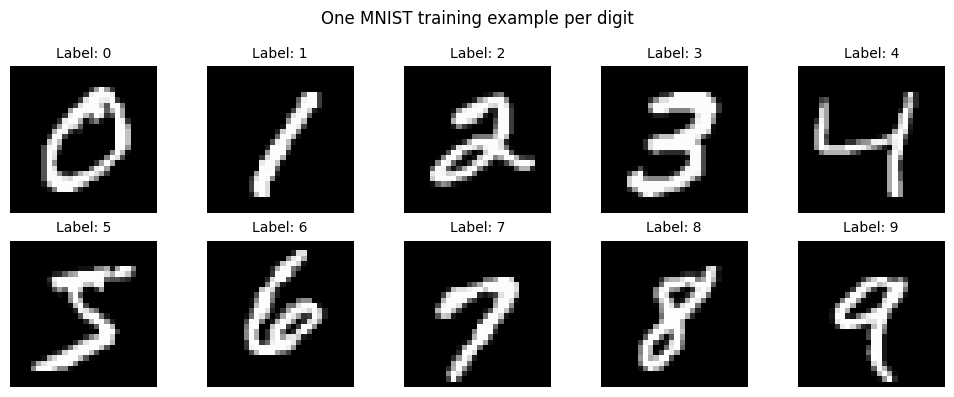

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for digit, ax in enumerate(axes.flat):
    index = np.flatnonzero(y_train == digit)[0]
    ax.imshow(X_train[index], vmin=0, vmax=255)
    ax.set_title(f"Label: {digit}")
    ax.axis("off")

fig.suptitle("One MNIST training example per digit")
fig.tight_layout()
plt.show()

## Pixel intensity distribution

Plot a deterministic subsample of training pixels to keep the visualization lightweight.
Values are displayed on the normalized 0–1 scale commonly used by the MLP.

In [6]:
# Taking every 100th pixel gives a representative sample without copying
# the full dataset.
sample_pixels = X_train.reshape(-1)[::100].astype(np.float32) / np.float32(255.0)

fig = px.histogram(
    x=sample_pixels,
    nbins=50,
    labels={"x": "Normalized pixel value", "y": "Count"},
    title="Distribution of MNIST pixel intensities (training sample)",
)
fig.update_layout(showlegend=False)
fig.show()

print(f"Sampled pixels: {sample_pixels.size:,}")
print(f"Sample mean:    {sample_pixels.mean():.4f}")
print(f"Sample std:     {sample_pixels.std():.4f}")

Sampled pixels: 470,400
Sample mean:    0.1295
Sample std:     0.3065


## Mean and variability by pixel

The mean image shows which pixels tend to be inked across the training set. The standard-deviation
image highlights pixels whose intensity varies most between images.

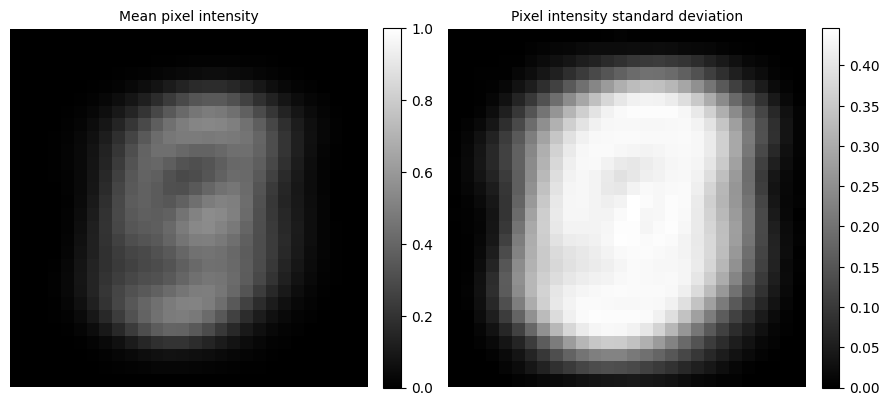

In [7]:
X_train_float = X_train.astype(np.float32) / np.float32(255.0)
mean_image = X_train_float.mean(axis=0)
std_image = X_train_float.std(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

images = [
    (mean_image, "Mean pixel intensity", 0.0, 1.0),
    (std_image, "Pixel intensity standard deviation", 0.0, float(std_image.max())),
]

for ax, (image, title, vmin, vmax) in zip(axes, images, strict=False):
    plot = ax.imshow(image, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(plot, ax=ax, fraction=0.046, pad=0.04)

fig.tight_layout()
plt.show()

## Shape and preprocessing preview

The MLP expects one feature vector per image: 28 × 28 pixels flattened to 784 values.
This cell previews flattening and normalization on a small batch without creating additional
full-size normalized copies of both datasets.

In [8]:
# reshape is a view for these contiguous image arrays; only the small preview
# is converted.
X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

preview = X_train_flat[:5].astype(np.float32) / np.float32(255.0)

print(f"Flattened training shape: {X_train_flat.shape}")
print(f"Flattened test shape:     {X_test_flat.shape}")
print(f"Preview shape:            {preview.shape}")
print(f"Preview dtype:            {preview.dtype}")
print(f"Preview range:            {preview.min():.1f}–{preview.max():.1f}")

Flattened training shape: (60000, 784)
Flattened test shape:     (10000, 784)
Preview shape:            (5, 784)
Preview dtype:            float32
Preview range:            0.0–1.0


## Exploration summary

- MNIST contains 60,000 training images and 10,000 test images.
- Each grayscale image is 28 × 28 pixels and corresponds to one of ten digit labels.
- Flattening produces 784 features per image; normalization maps pixel values to 0–1.
- The test split remains untouched for final evaluation.

Next: implement the NumPy layers, loss, backpropagation, and training loop in
`01_MLP_From_Scratch.ipynb`.